In [1]:
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.patches as patches
import pickle
import sys
sys.path.insert(0,'../src/')



from utils import *
from multiply_connected_pipe import *
from pipe_system import PipeSystem
from abstract_pipe import *
from curve import *

# Set up plotting parameters
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12


#### geometry creation

In [9]:
# Goal 1: Create T-shaped and L-shaped pipe junctions

print("Creating 十-shaped pipe junctions...")


pt1 = 10
pt2 = 10 * np.exp(2*np.pi*1j/3)
pt3 = 10 * np.exp(4*np.pi*1j/3)

pt1 = np.array([pt1.real,pt1.imag])
pt2 = np.array([pt2.real,pt2.imag])
pt3 = np.array([pt3.real,pt3.imag])





ls = np.array([pt1,pt2,pt3])

rs = np.array([1,1,1])

corner_size = 1

pipe = NLets(ls,rs,corner_size)
pipe.build_geometry(required_tol=1e-10)

Creating 十-shaped pipe junctions...
1
1
1


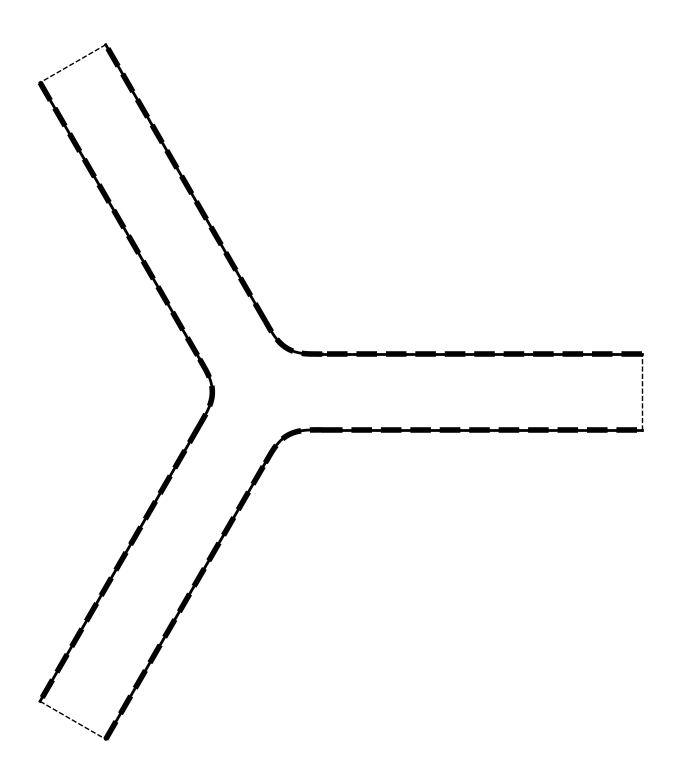

In [10]:
# Visualize the pipe geometries using the boundary plotting method
fig, ax = plt.subplots(tight_layout=True)

# Plot T-shaped pipe
ax.set_aspect('equal')
ax.axis('off')

pipe.exterior_boundary.plot_plyg_bdr(ax,color='k')
plt.show()

In [11]:
# Goal 2: Solve for characteristic flows with Poiseuille boundary conditions
print("Building complete solver for T-shaped pipes...")
# Build complete solvers - this includes geometry, matrices, and flow solutions
eps = 1e-8
pipe.build(required_tol=eps, fmm=True, density=20)

Building complete solver for T-shaped pipes...




/Users/haiy/git/fmm2d/python/fmm2dpy/fmm2d.py:894: ComplexWarning: Casting complex values to real discards the imaginary part
  out.pottarg,out.gradtarg,out.ier = lfmm.cfmm2d_t_d_g(eps,sources,dipstr,targets)


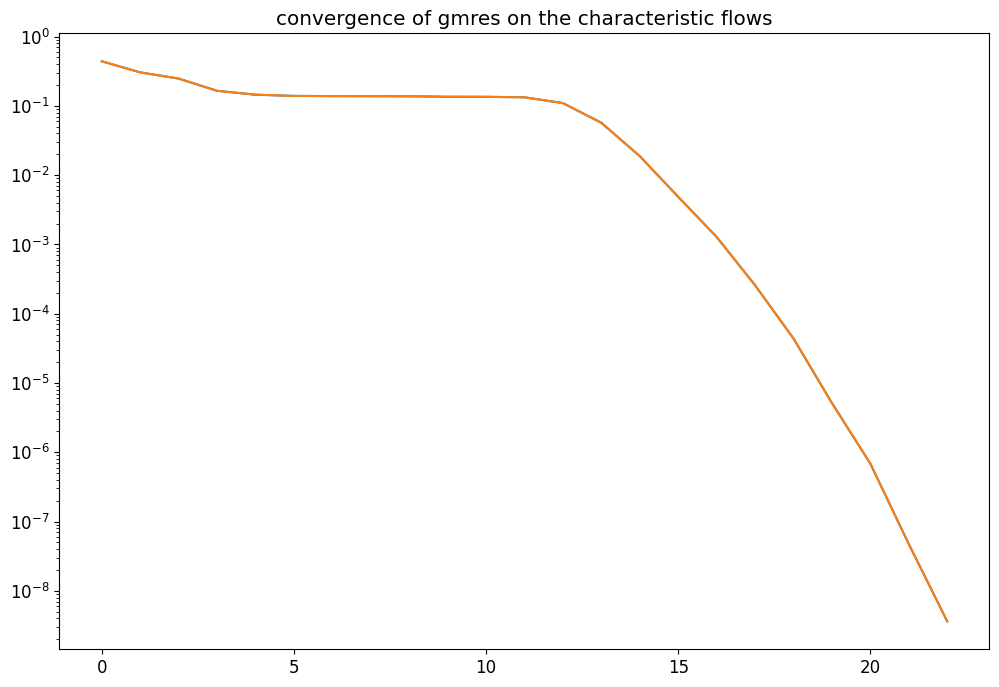

In [12]:
for c in pipe.callbacks:
    plt.semilogy(c.residuals)
plt.title('convergence of gmres on the characteristic flows')
plt.show()

#### flows 

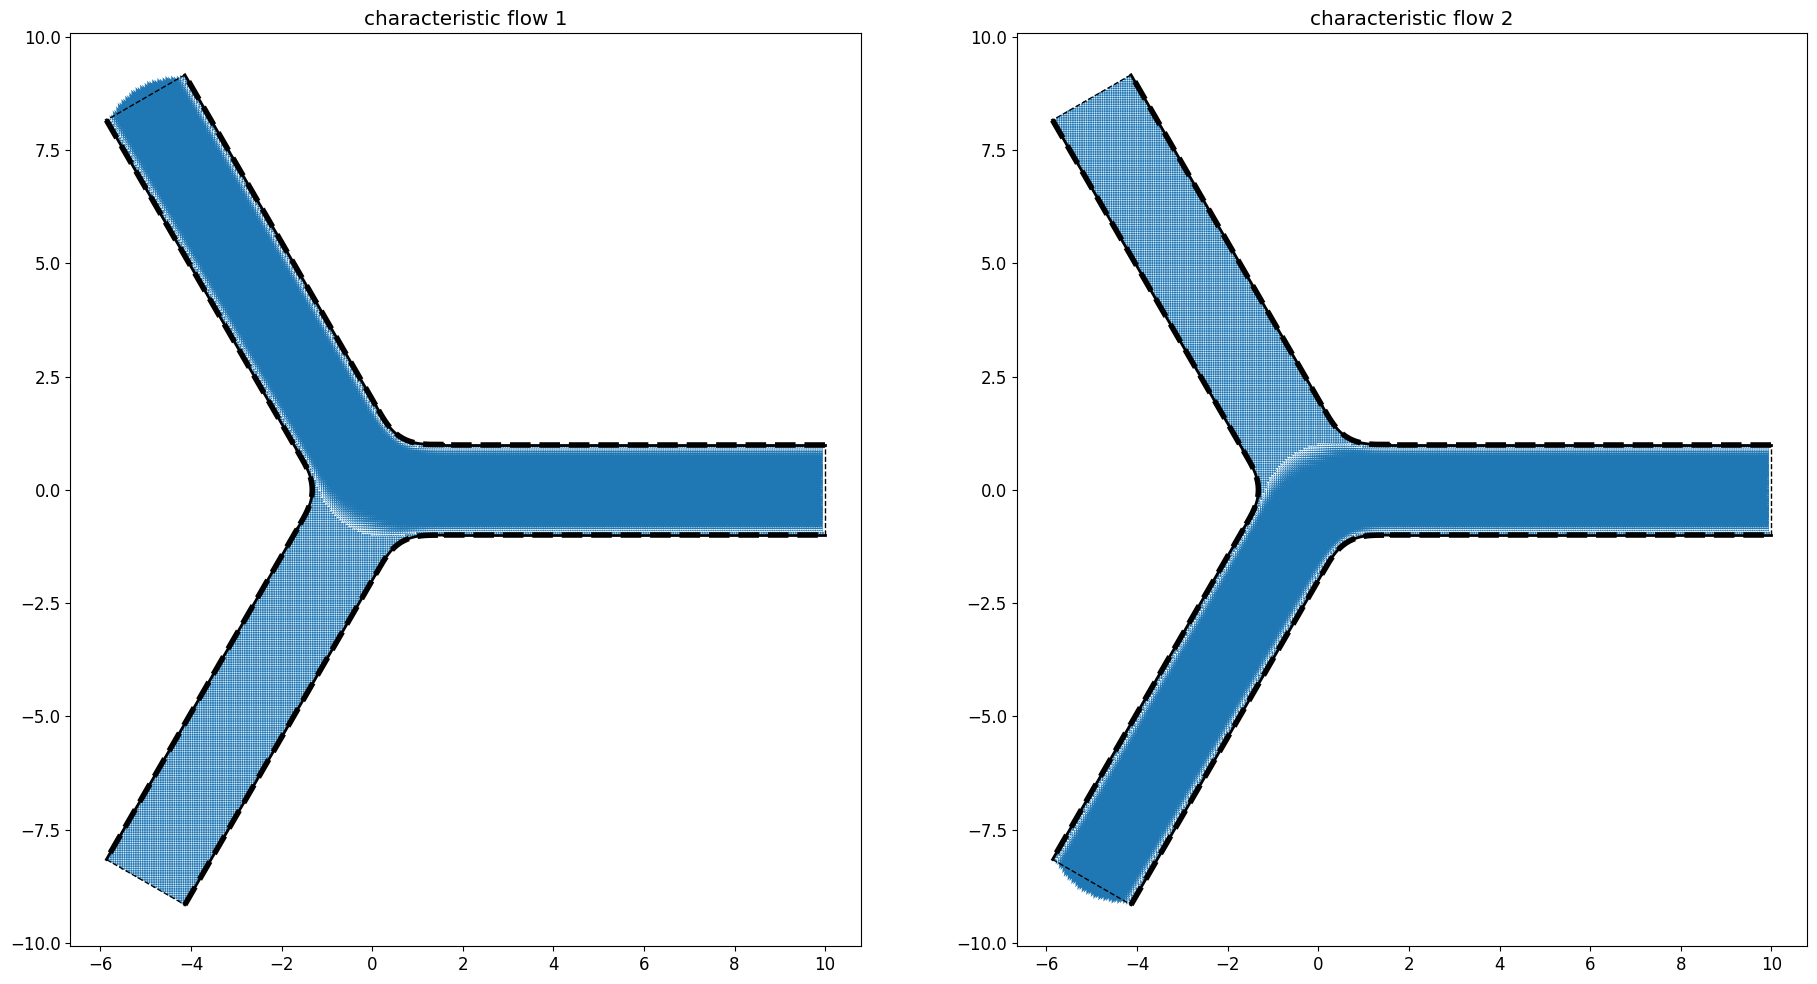

In [13]:
xs = pipe.xs
ys = pipe.ys



fig, axes = plt.subplots(1,pipe.n_flows, figsize=(pipe.n_flows*10,10),tight_layout=True)

def one_hot(i,n):
    return np.eye(n)[i]

for i in range(pipe.n_flows):
    ax = axes[i]
    ax.set_aspect('equal')
    
    u,v,p,o = pipe.fields_with_fluxes(one_hot(i,pipe.n_flows),0,0)
    pipe.exterior_boundary.plot_plyg_bdr(ax, color='k')
    ax.quiver(xs, ys, u, v, scale=40, color='C0', width=0.003)
    ax.set_title(f'characteristic flow {i+1}')

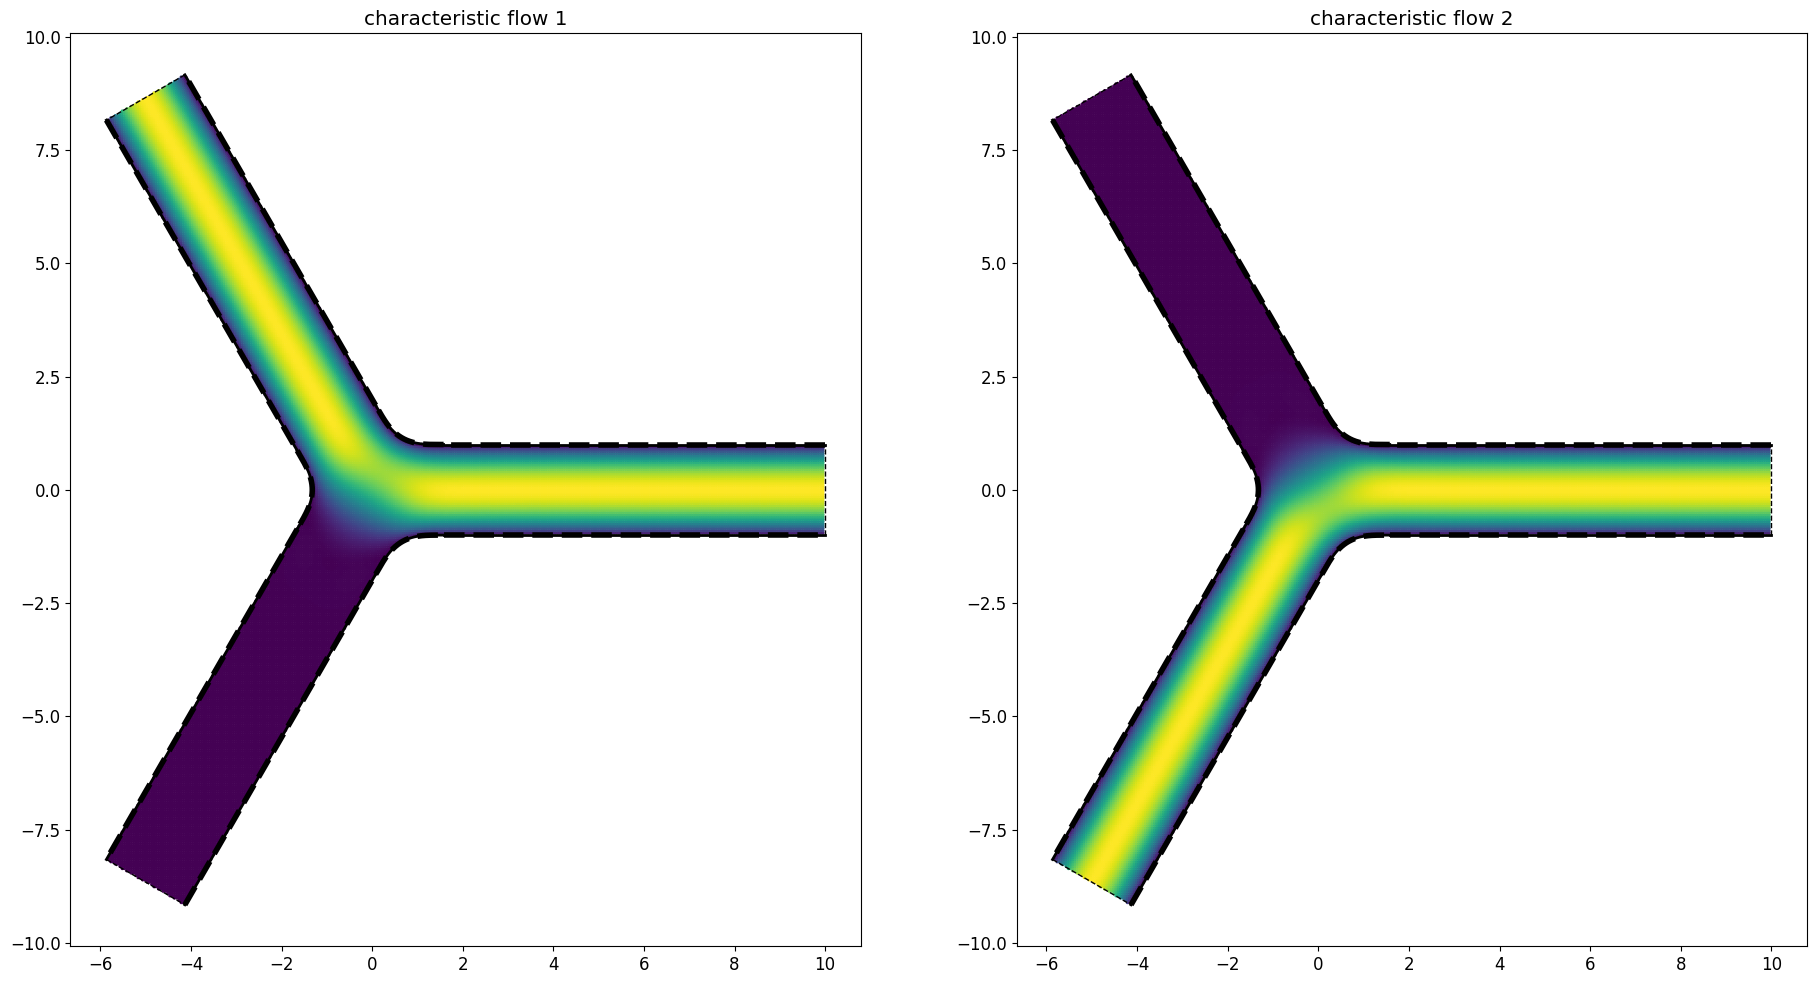

In [15]:
xs = pipe.xs
ys = pipe.ys


fig, axes = plt.subplots(1,pipe.n_flows, figsize=(pipe.n_flows*10,10),tight_layout=True)

def one_hot(i,n):
    return np.eye(n)[i]

for i in range(pipe.n_flows):
    ax = axes[i]
    ax.set_aspect('equal')
    
    u,v,p,o = pipe.fields_with_fluxes(one_hot(i,pipe.n_flows),0,0)
    pipe.exterior_boundary.plot_plyg_bdr(ax, color='k')
    ax.scatter(xs, ys, c = np.sqrt(u**2+v**2), s = 2)
    ax.set_title(f'characteristic flow {i+1}')

#### assembling the pipes

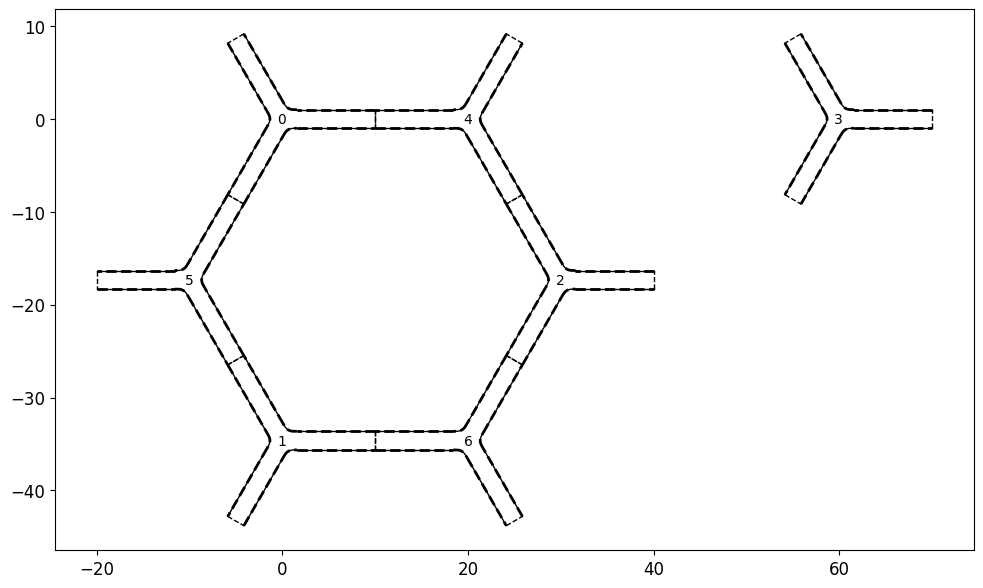

In [ ]:
fig,ax = plt.subplots(figsize=(10,10),tight_layout=True)

n_rep_1 = 3
n_rep_2 = 3


pipes = [
    RealPipe(pipe,0,0,0), 
    RealPipe(pipe,0,-4*pt2[1],0),
    RealPipe(pipe,20-2*pt2[0],-2*pt2[1],0),
    RealPipe(pipe,60,0,0),
    RealPipe(pipe,20,0,np.pi),
    RealPipe(pipe,-10,-2*pt2[1],np.pi),
    RealPipe(pipe,20,-4*pt2[1],np.pi),
    
]


for i,p in enumerate(pipes):
    p.plot_plyg_bdr(ax)
    x = np.mean(p.xs) - 0.5
    y = np.mean(p.ys) - 0.5
    ax.text(x,y,f'{i}',fontsize=10)

ax.set_aspect('equal')

plt.show()

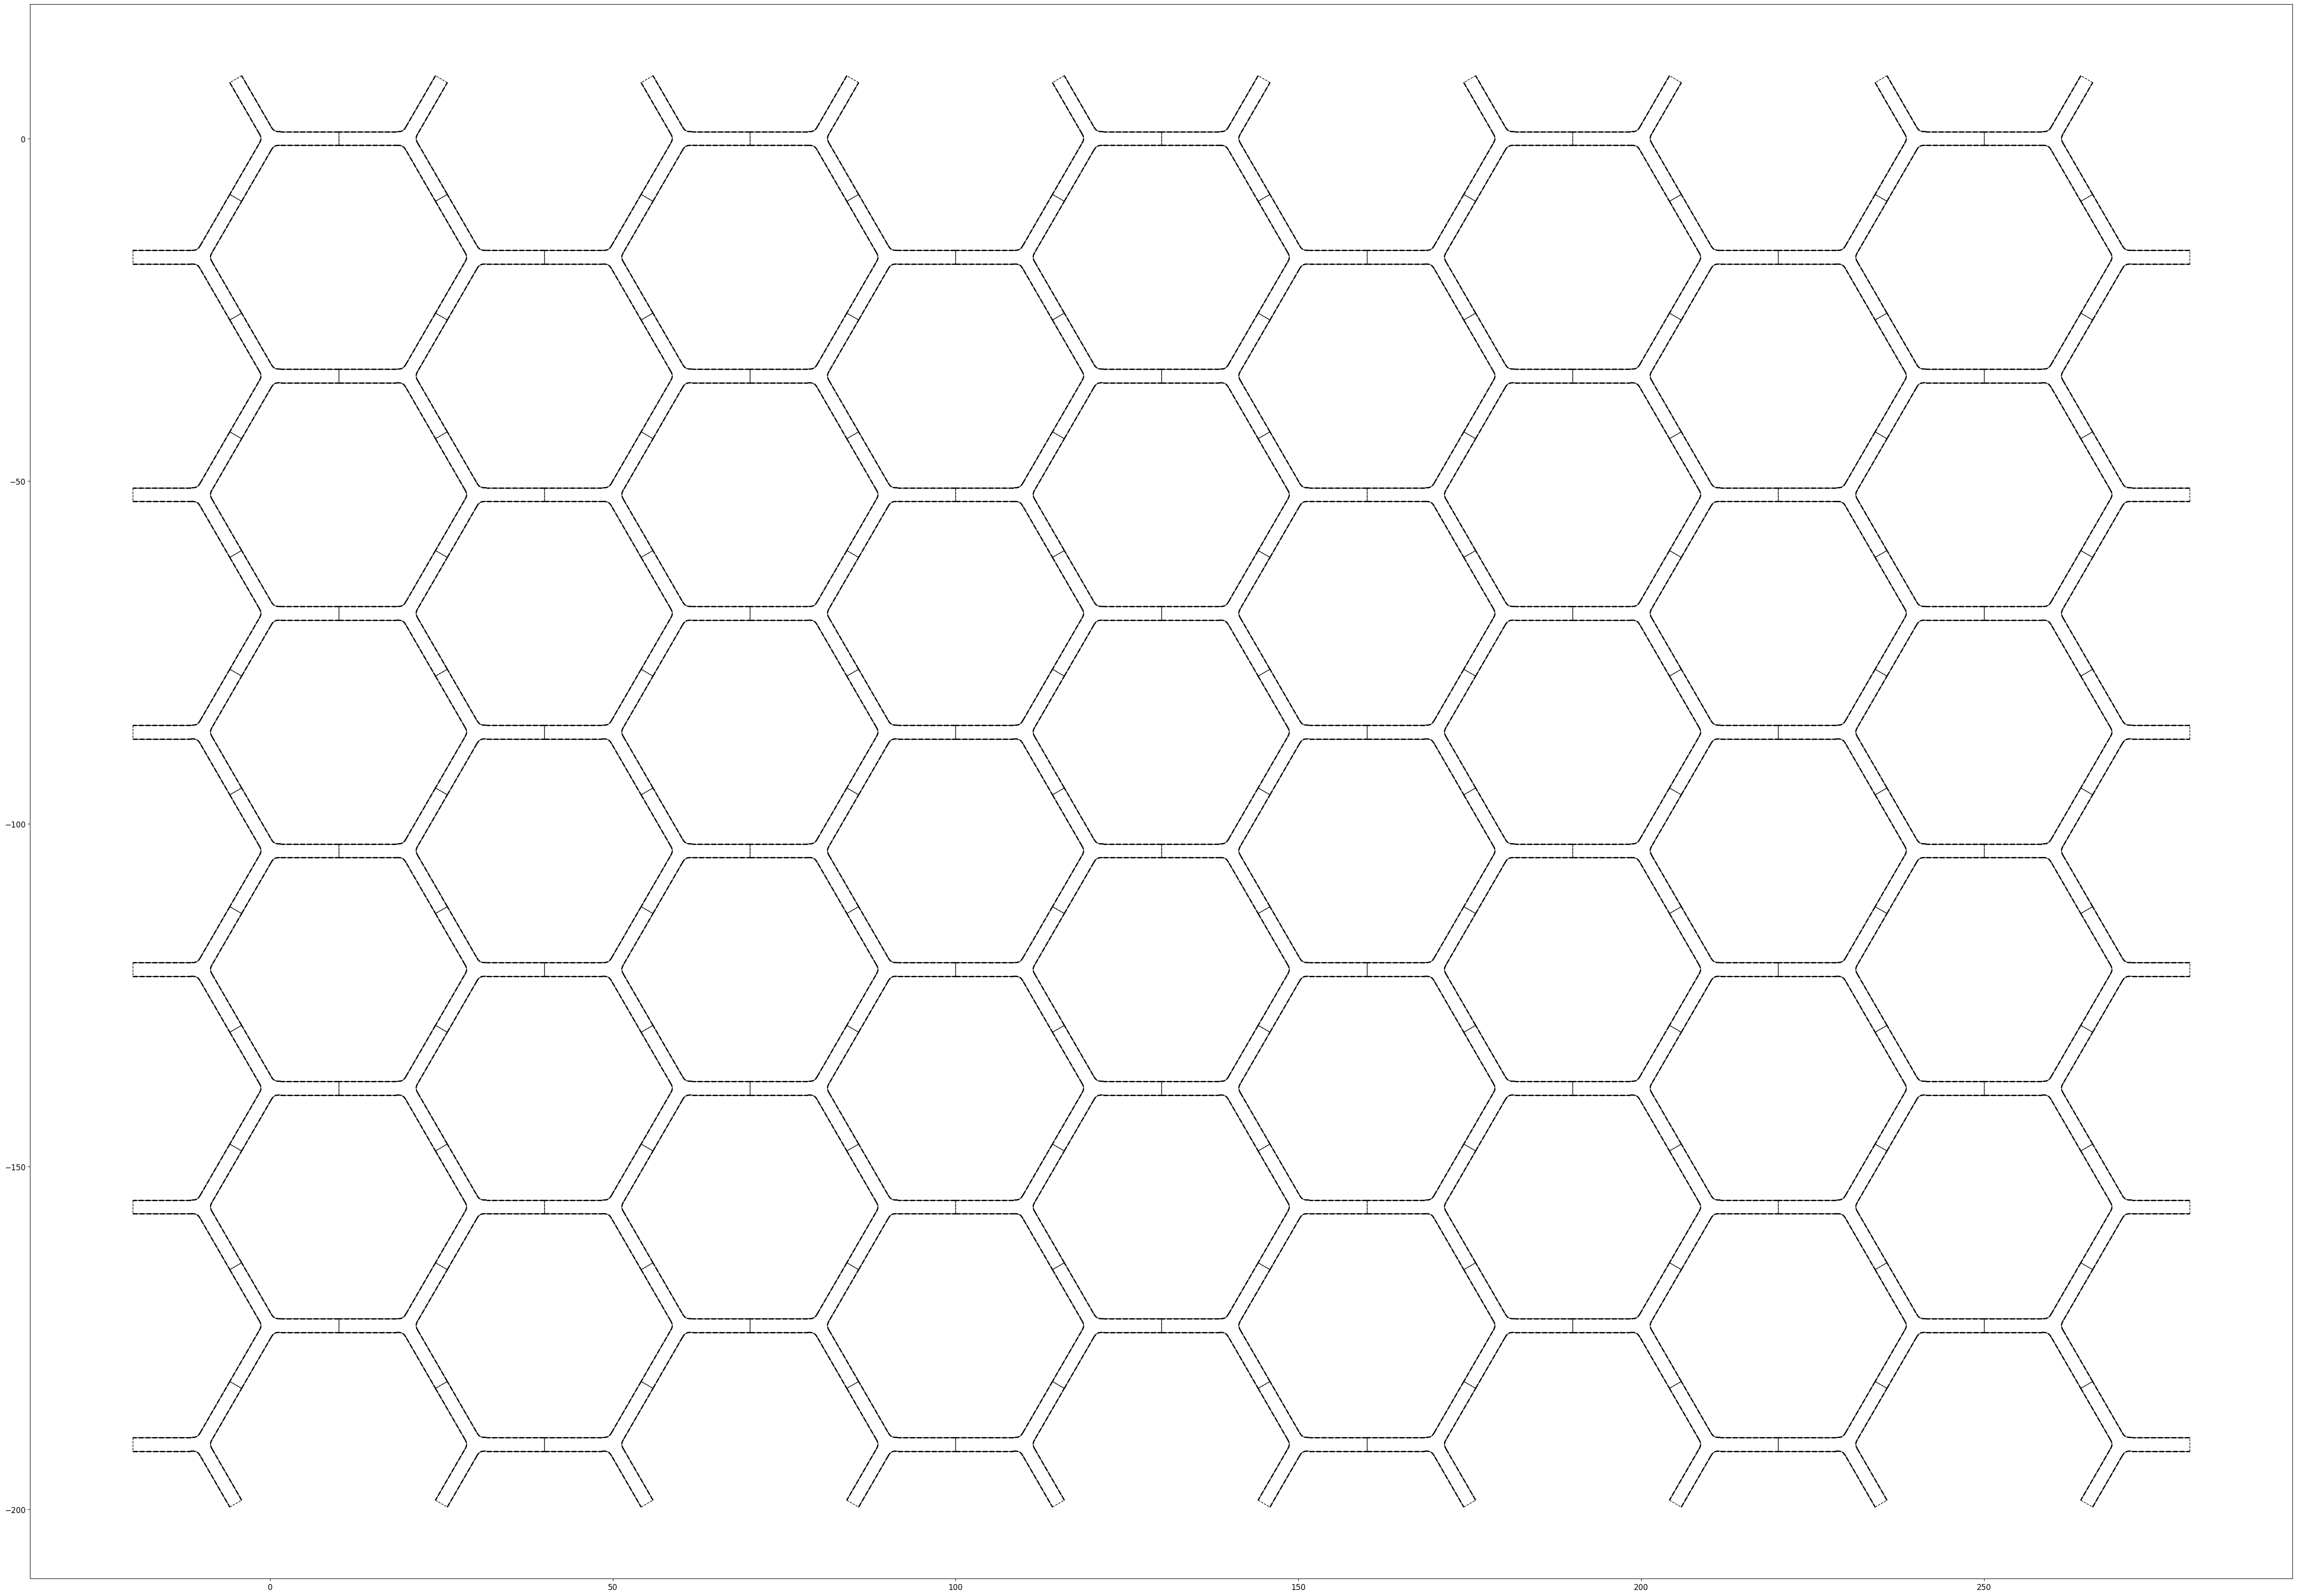

In [58]:
fig,ax = plt.subplots(figsize=(50,50),tight_layout=True)

n_rep_1 = 5
n_rep_2 = 6


pipes = [RealPipe(pipe,60*i,-4*pt2[1]*j,0) for i in range(n_rep_1) for j in range(n_rep_2)] + \
    [RealPipe(pipe,20+60*i,-4*pt2[1]*j,np.pi) for i in range(n_rep_1) for j in range(n_rep_2)] + \
    [RealPipe(pipe,-10+60*i,-2*pt2[1]-4*pt2[1]*j,np.pi) for i in range(n_rep_1) for j in range(n_rep_2)] + \
    [RealPipe(pipe,30+60*i,-2*pt2[1]-4*pt2[1]*j,0) for i in range(n_rep_1) for j in range(n_rep_2)]


for i,p in enumerate(pipes):
    p.plot_plyg_bdr(ax)

ax.set_aspect('equal')
plt.show()

In [59]:

import pickle

with open('pipe.pkl', 'wb') as f:
    pickle.dump(pipe, f)


In [ ]:
import pickle

with open('pipe.pkl', 'rb') as f:
    pipe = pickle.load(f)
